# Milestone 3 Data visualization

### Task 1: Monthly Revenue Trend Chart

In [1]:
# Setup

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

df = pd.read_excel("../data/Coffee Shop Sales.xlsx")
df["line_revenue"] = df["transaction_qty"] * df["unit_price"]
df["month"] = pd.to_datetime(df["transaction_date"]).dt.to_period('M')


month
2023-01     81677.74
2023-02     76145.19
2023-03     98834.68
2023-04    118941.08
2023-05    156727.76
2023-06    166485.88
Freq: M, Name: line_revenue, dtype: float64

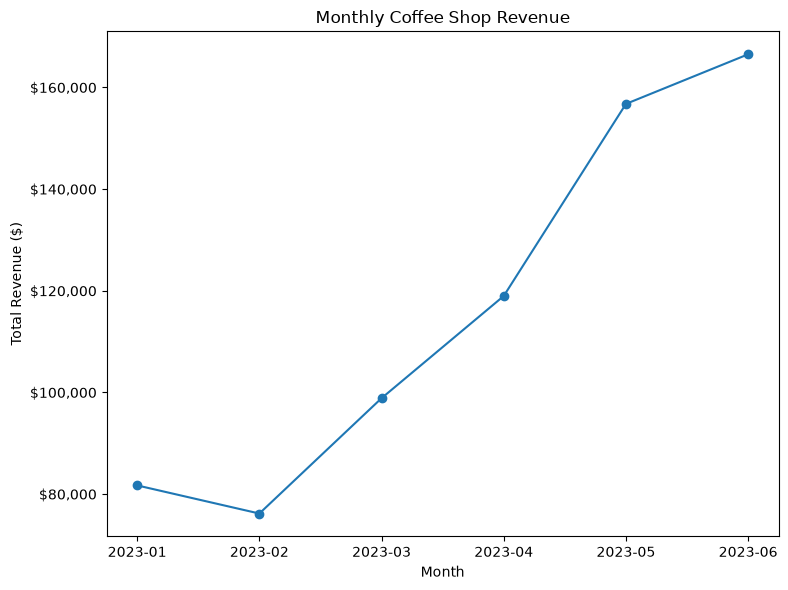

In [2]:
# Task 1: Monthly Revenue Trend Chart

total_revenue_monthly = df.groupby("month")["line_revenue"].sum().sort_index()
display(total_revenue_monthly)

plt.figure(figsize=(8, 6))

plt.plot(
    total_revenue_monthly.index.astype(str),
    total_revenue_monthly.values,
    marker="o"
)

plt.title("Monthly Coffee Shop Revenue")
plt.xlabel("Month")
plt.ylabel("Total Revenue ($)")

# Step 5: Format the Y-axis as dollars
plt.gca().yaxis.set_major_formatter(
    mtick.StrMethodFormatter("${x:,.0f}")
)


# Step 6: Display the chart
plt.tight_layout()
plt.show()


### Findings

There is a continous trend of increasing revenue with steeper growth from April to May.

### Task 2: Coffee Shop Revenue by Location Chart

store_location
Lower Manhattan    230057.25
Astoria            232243.91
Hell's Kitchen     236511.17
Name: line_revenue, dtype: float64

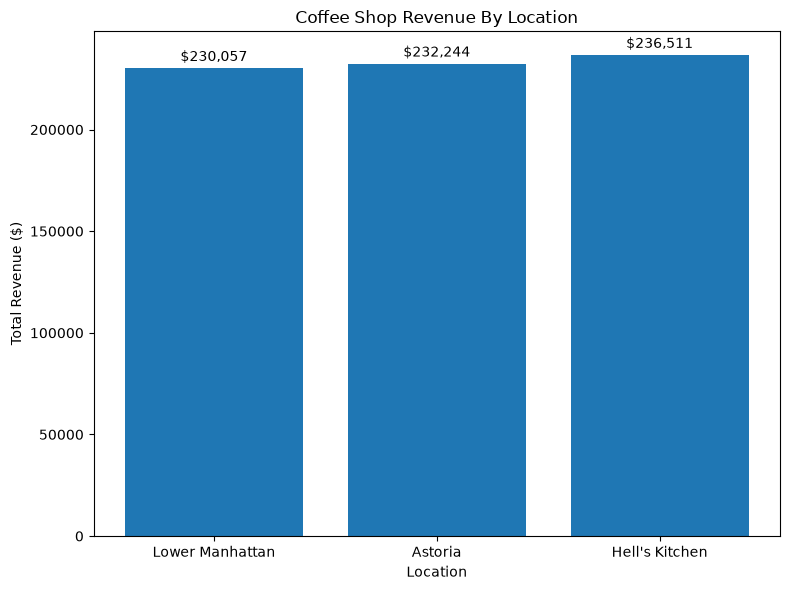

In [3]:
revenue_by_location = df.groupby("store_location")["line_revenue"].sum().sort_values()
display(revenue_by_location)

plt.figure(figsize=(8, 6))

bars = plt.bar(
    revenue_by_location.index,
    revenue_by_location.values
)

plt.bar_label(
    bars,
    labels=[f"${v:,.0f}" for v in revenue_by_location.values],
    padding=3
)

plt.title("Coffee Shop Revenue By Location")
plt.xlabel("Location")
plt.ylabel("Total Revenue ($)")


plt.tight_layout()
plt.show()


### Which store generates the highest revenue?
The store with the highest revenue is Hell's Kitchen.


### What is the dollar difference between the highest- and lowest-performing stores?
The dollar difference is approx. $6000.


### Does the highest-revenue store necessarily have the most transactions?
Not necessarily, it depends on the price of the products, too.

### Task 3: Top 10 Products by Revenue Chart

[Text(0, 3, '$91,406'),
 Text(0, 3, '$77,082'),
 Text(0, 3, '$72,416'),
 Text(0, 3, '$70,035'),
 Text(0, 3, '$47,932'),
 Text(0, 3, '$47,540'),
 Text(0, 3, '$38,781'),
 Text(0, 3, '$37,746'),
 Text(0, 3, '$36,866'),
 Text(0, 3, '$31,984'),
 Text(0, 3, '$25,656'),
 Text(0, 3, '$23,852'),
 Text(0, 3, '$19,794'),
 Text(0, 3, '$14,584'),
 Text(0, 3, '$8,510'),
 Text(0, 3, '$7,444'),
 Text(0, 3, '$6,798'),
 Text(0, 3, '$6,163'),
 Text(0, 3, '$6,085'),
 Text(0, 3, '$5,560'),
 Text(0, 3, '$4,301'),
 Text(0, 3, '$3,294'),
 Text(0, 3, '$2,730'),
 Text(0, 3, '$2,728'),
 Text(0, 3, '$2,712'),
 Text(0, 3, '$2,324'),
 Text(0, 3, '$1,680'),
 Text(0, 3, '$1,471'),
 Text(0, 3, '$1,340')]

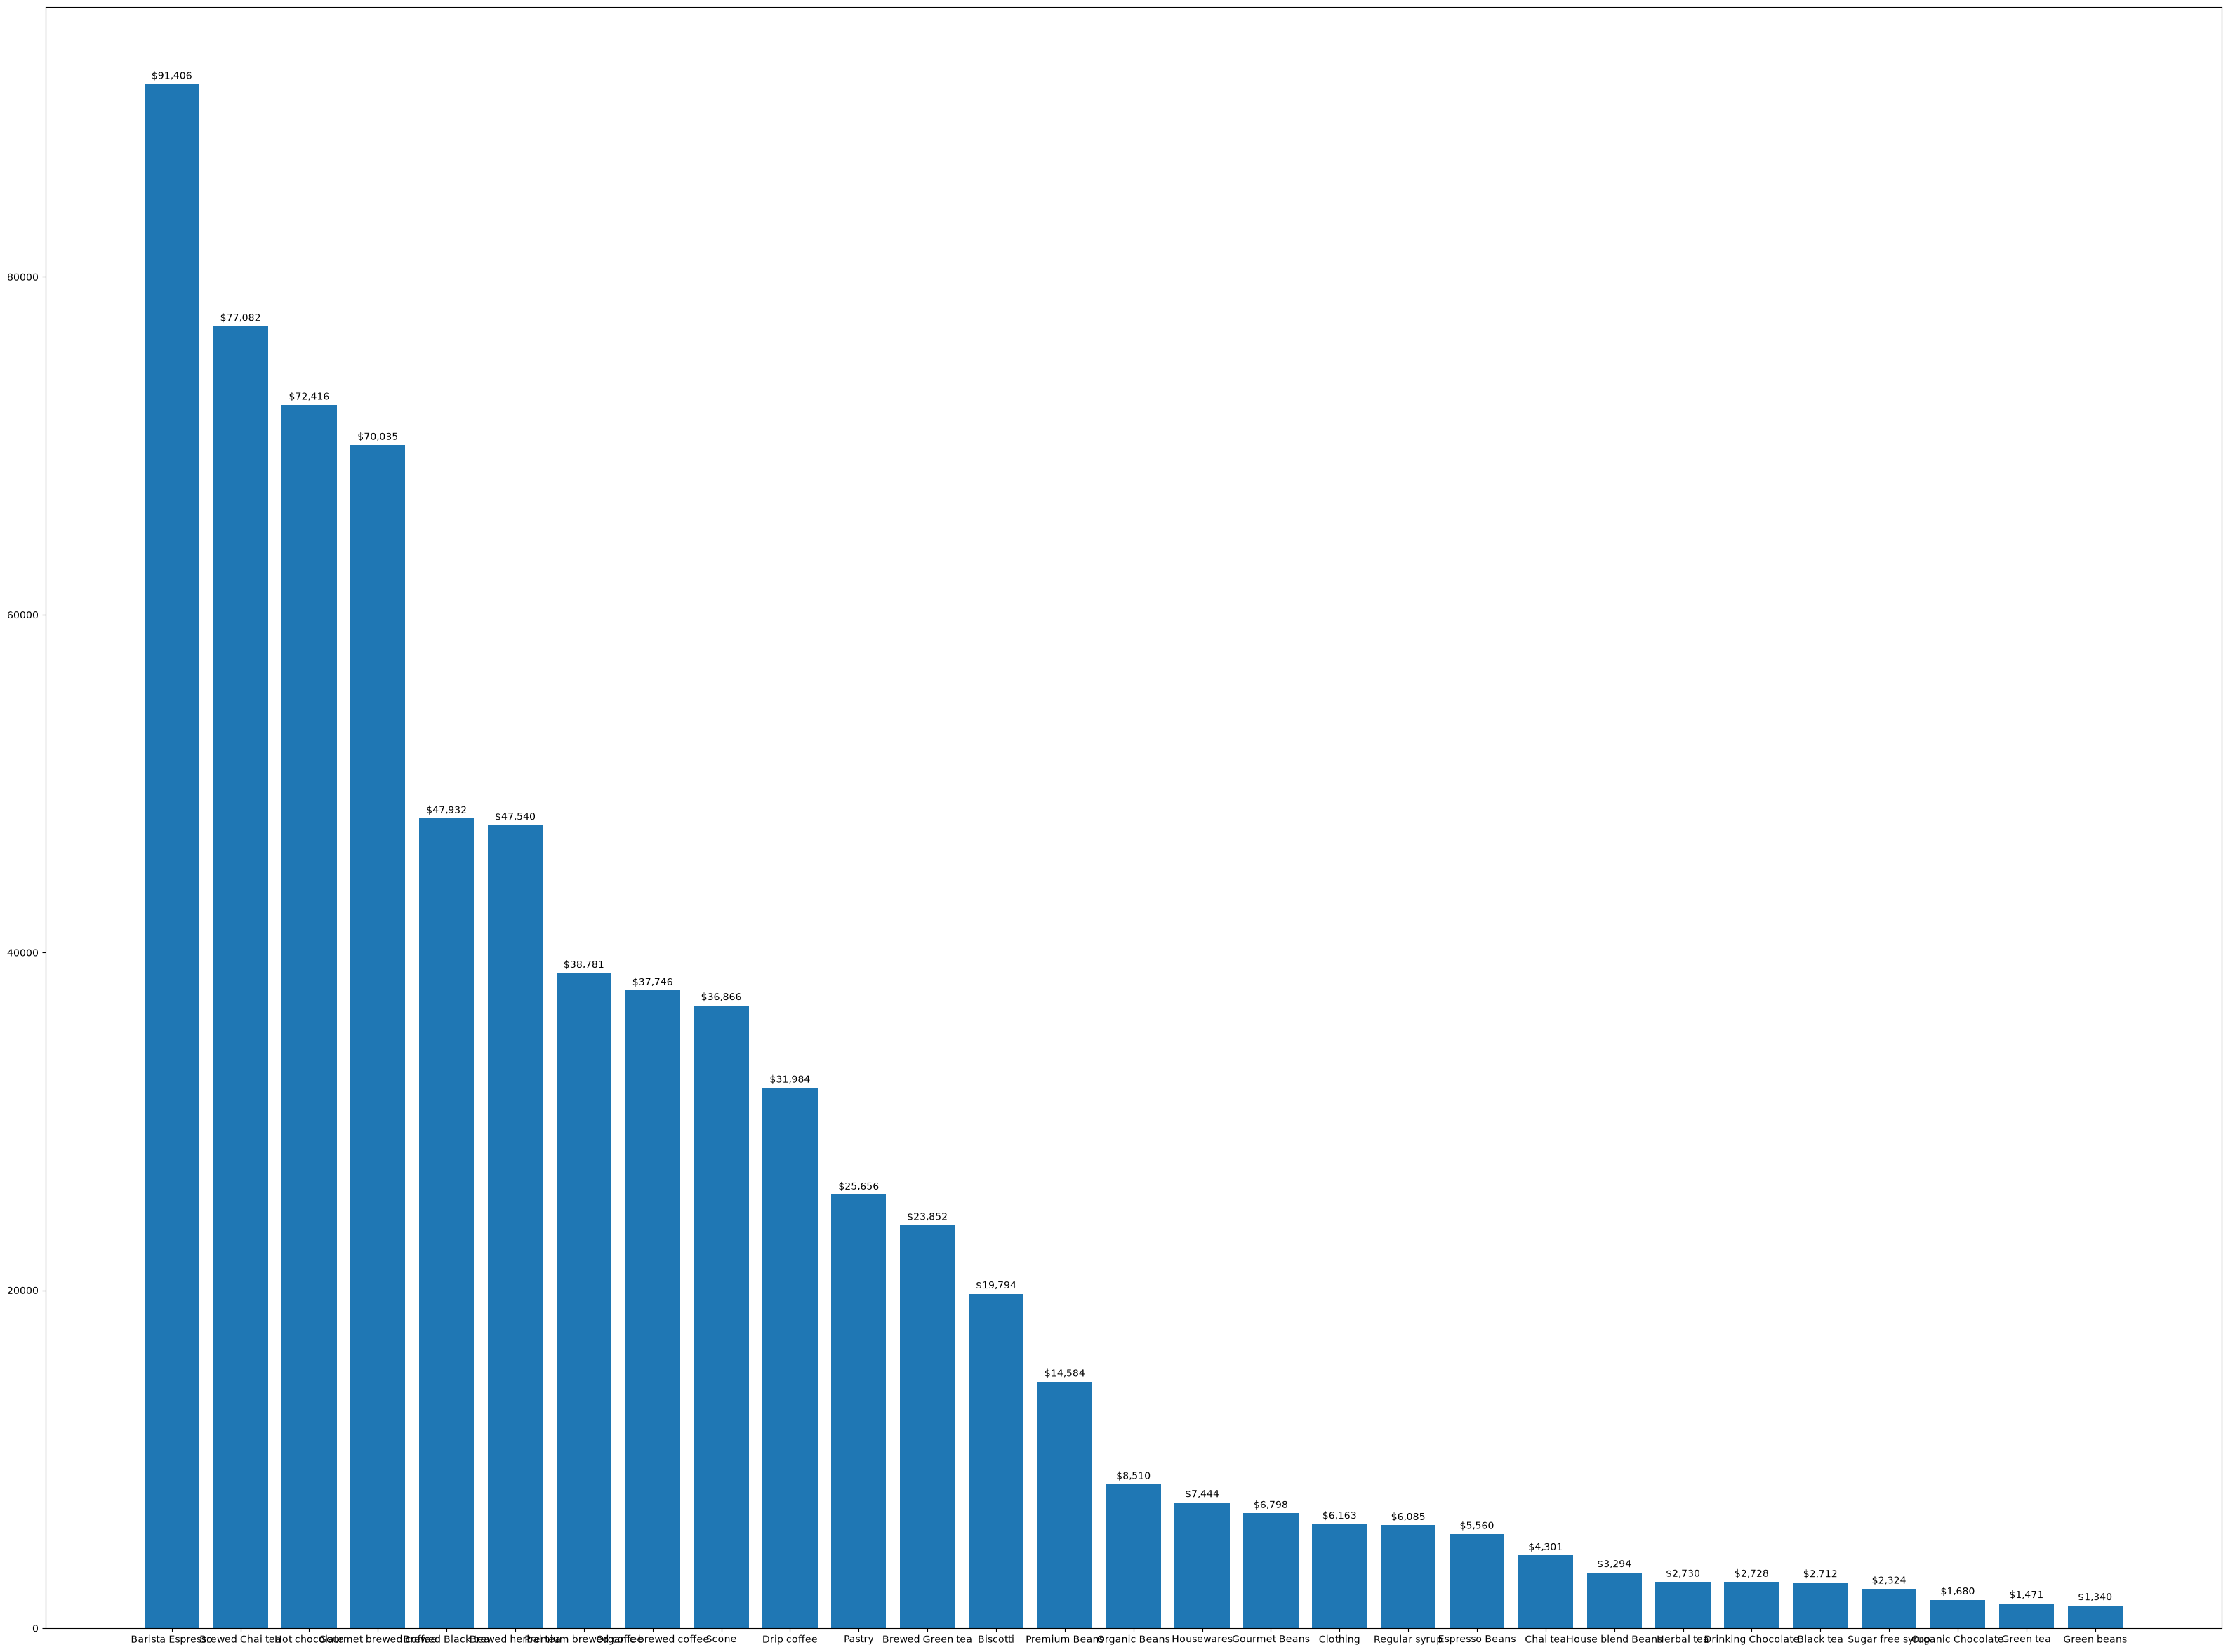

In [14]:
revenue_by_product = df.groupby("product_type")["line_revenue"].sum().sort_values(ascending=False)

plt.figure(figsize=(40, 30))

bars = plt.bar(
    revenue_by_product.index,
    revenue_by_product.values
)

plt.bar_label(
    bars,
    labels=[f"${v:,.0f}" for v in revenue_by_product.values],
    padding=3
)



### Which individual product generates the most revenue?
The Barista Esperesso generates the most revenue, at $91K.


### How much revenue does it generate compared with the 10th-ranked product?
Compared to the drip coffee, the Barista Espresso generates about $60K more.


### Does generating the most revenue necessarily mean a product sells the most units?
Not necessarily; it also depends on how much each product sells for per unit.